# TBG wavefunctions from first-principles density functional theory

The following notebook shows how to read the DFT wavefunctions of TBG, construct them on a real-space grid of your choice, and visualize the wavefunction density, as in [Wavefunction textures in twisted bilayer graphene from first principles](https://journals.aps.org/prb/abstract/10.1103/2m63-b51d). `Matplotlib`, `numpy`, `scipy`, and `sisl` are required.

The results in this notebook and in the paper were generated with `sisl` version 0.15.2, which we recommend installing via
```
pip install sisl==0.15.2
```
The other package versions used were `python` 3.11.11, `numpy` 1.26.4, `scipy` 1.15.1, and `matplotlib` 3.10.0.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy import ndimage
from scipy.spatial import cKDTree
import sisl as si

print(f"sisl version: {si.__version__}")

sisl version: 0.15.2


In [2]:
def angles(N):
    """
    Return the angle corresponding to an integer N (see angles.txt)
    """
    return np.round(
        np.arccos(
            ((N - 1) ** 2 + 4 * N * (N - 1) + N ** 2) / (2 * ((N - 1) ** 2 + N * (N - 1) + N ** 2))
        ) * 180 / np.pi,
        10
    )

## Reading the wavefunction files

Constructing a wavefunction in real space requires three files:
- `DFT-wavefunctions/Gamma-*.WFSX`: the `Siesta` wavefunction files (binary format). Each file contains the eigenstates at the $\Gamma$ point of the moir\'e Brillouin zone closest to the charge neutrality point (CNP): the four flat-band states and eight remote-band states on either side. For each eigenstate $n$, the file stores the band energy $E_n$ and the coefficients $c_{n,i\mu}$ of the eigenstate in the `Siesta` basis of numerical atomic orbitals $\phi_\mu$ centered on each atom $i$. Since the states are at $\Gamma$, the coefficients are real. Note that for the largest angle, $21.79^\circ$, more wavefunctions are provided than the four flat-band states and eight remote-band states on either side as the "flat band manifold" at that angle crosses through remote bands (you can plot that band structure in `bands-tight-binding.ipynb` to see this).
- `DFT-wavefunctions/C.ion.xml`: the carbon basis set, which is the same for all twist angles. Each atom has 9 orbitals: one $2s$, three $2p$, and five $3d$ (polarization) orbitals. Each orbital is a numerical radial function multiplied by a real spherical harmonic, and is strictly zero beyond a cutoff radius of at most $3.57$ Angstroms.
- `relaxed-atomic-structures/relaxed-*.fdf`: the lattice vectors and relaxed atomic positions (see `relaxed_structures.ipynb`). The atoms are listed in the same order as the coefficients in the wavefunction files. They are grouped into four blocks of equal size, one for each sublattice: $A$ and $B$ of the bottom layer $L_1$ ($z \approx 18.25$ Angstroms), followed by $A$ and $B$ of the top layer $L_2$ ($z \approx 21.75$ Angstroms).

The cell below loads all three for an angle of $1.05^\circ$:

In [3]:
N = 32                                                                                                                      # 1.05 degrees
n_atoms = int(np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=7, max_rows=1, usecols=[1]).item())          # Load number of atoms
lattice = np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=2, max_rows=3)                                   # Load lattice vectors (shape 3 x 3)
positions = np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=17, max_rows=n_atoms, usecols=[0, 1, 2])       # Load relaxed atomic positions (shape n_atoms x 3)

basis = si.get_sile("DFT-wavefunctions/C.ion.xml").read_basis()                                                             # Load basis orbitals

eigenstates = si.get_sile(f"DFT-wavefunctions/Gamma-{N}.WFSX").read_eigenstate()                                            # Load eigenstates at Gamma
energies = eigenstates.eig                                  # Band energies in eV (shape n_states)
coefficients = eigenstates.state.astype(np.float64)         # Coefficients c_{n, i mu} (shape n_states x (n_atoms * 9))
siesta_indices = eigenstates.info["index"] + 1              # Band index of each state (sisl counts from 0, Siesta from 1)

print(f"{n_atoms} atoms, {len(energies)} states, {coefficients.shape[1]} coefficients per state")
print(basis)

11908 atoms, 20 states, 107172 coefficients per state
Atom{C, Z: 6, mass(au): 12.01100, maxR: 3.56708,
 AtomicOrbital{2sZ1, q0: 2.0, SphericalOrbital{l: 0, R: 3.22760665461926, q0: 2.0}},
 AtomicOrbital{2pyZ1, q0: 0.6666666666666666, SphericalOrbital{l: 1, R: 3.5670800017726947, q0: 2.0}},
 AtomicOrbital{2pzZ1, q0: 0.6666666666666666, SphericalOrbital{l: 1, R: 3.5670800017726947, q0: 2.0}},
 AtomicOrbital{2pxZ1, q0: 0.6666666666666666, SphericalOrbital{l: 1, R: 3.5670800017726947, q0: 2.0}},
 AtomicOrbital{3dxyZ1, q0: 0.0, SphericalOrbital{l: 2, R: 3.309319440391631, q0: 0.0}},
 AtomicOrbital{3dyzZ1, q0: 0.0, SphericalOrbital{l: 2, R: 3.309319440391631, q0: 0.0}},
 AtomicOrbital{3dz2Z1, q0: 0.0, SphericalOrbital{l: 2, R: 3.309319440391631, q0: 0.0}},
 AtomicOrbital{3dxzZ1, q0: 0.0, SphericalOrbital{l: 2, R: 3.309319440391631, q0: 0.0}},
 AtomicOrbital{3dx2-y2Z1, q0: 0.0, SphericalOrbital{l: 2, R: 3.309319440391631, q0: 0.0}}
}


## Selecting states

The band energies in the wavefunction files are the eigenvalues from `Siesta`. To be consistent with the band structures in `DFT-band-structures/`, we define the charge neutrality point (CNP) to have an energy of $0$ eV, as in `bands_tight_binding.ipynb`. Since each carbon atom contributes 4 valence electrons and the bands are spin degenerate, there are $2 \times$ `n_atoms` occupied bands at the CNP, so the four flat bands have `Siesta` band indices $2n_{\rm atoms} - 1$ to $2n_{\rm atoms} + 2$.

Many states at $\Gamma$ are degenerate due to symmetry. Within a degenerate multiplet, the individual eigenstates returned by the diagonalization are arbitrary linear combinations of each other, so only the density summed over a complete multiplet is meaningful. The cell below lists the states in the file and groups them into multiplets:

In [4]:
# Load the DFT bands to find the Dirac point energy at K
Nkpoints = 31
bands_E = np.loadtxt(f"DFT-band-structures/bands-{N}.dat")[:, 1].reshape((-1, Nkpoints))
flat_band_index = len(bands_E) // 2 - 2                                  # Lowest flat band in bands-*.dat
i_flat = np.flatnonzero(siesta_indices == 2 * n_atoms - 1)[0]            # Lowest flat band in the wavefunction file

# Gamma is k-point Nkpoints // 3 and K is k-point 0 in bands-*.dat
E_dirac = energies[i_flat] - (bands_E[flat_band_index, Nkpoints // 3] - bands_E[flat_band_index, 0])
energies_meV = (energies - E_dirac) * 1000

# Group degenerate states (the splittings within a multiplet are below 0.1 meV)
multiplets = np.concatenate([[0], np.cumsum(np.diff(energies) > 1e-3)])

print(f"{'state':>5} {'Siesta index':>13} {'E - E_F (meV)':>14} {'multiplet':>10}")
for i, (index, E, m) in enumerate(zip(siesta_indices, energies_meV, multiplets)):
    flat = "  flat band" if 2 * n_atoms - 1 <= index <= 2 * n_atoms + 2 else ""
    print(f"{i:>5} {index:>13} {E:>14.2f} {m:>10}{flat}")

state  Siesta index  E - E_F (meV)  multiplet
    0         23807        -219.55          0
    1         23808        -219.55          0
    2         23809        -219.52          0
    3         23810        -219.52          0
    4         23811         -38.30          1
    5         23812         -38.29          1
    6         23813         -38.28          1
    7         23814         -38.27          1
    8         23815         -12.50          2  flat band
    9         23816         -12.50          2  flat band
   10         23817          17.25          3  flat band
   11         23818          17.26          3  flat band
   12         23819          51.13          4
   13         23820          51.14          4
   14         23821          51.15          4
   15         23822          51.16          4
   16         23823         220.97          5
   17         23824         220.97          5
   18         23825         220.99          5
   19         23826         221.00  

Select the states to construct by their position in the file (the `state` column above). Below, we select the two degenerate valence flat-band states at $\Gamma$:

In [5]:
selected = [8, 9]

# Check that the selection contains complete multiplets
for m in np.unique(multiplets[selected]):
    if not set(np.flatnonzero(multiplets == m)) <= set(selected):
        print(f"Warning: the selection only includes part of multiplet {m} (states {np.flatnonzero(multiplets == m)})")
print(f"Selected Siesta band indices {siesta_indices[selected]} at E - E_F = {np.round(energies_meV[selected], 2)} meV")

Selected Siesta band indices [23815 23816] at E - E_F = [-12.5 -12.5] meV


## Constructing the wavefunction on a real-space grid

The wavefunction of state $n$ at a point ${\bf r}$ is
$$\psi_n({\bf r}) = \sum_{\bf R} \sum_{i} \sum_{\mu} c_{n,i\mu}\, \phi_\mu({\bf r} - {\boldsymbol \tau}_i - {\bf R}),$$
where ${\boldsymbol \tau}_i$ is the position of atom $i$ in the moir\'e cell and ${\bf R} = n{\bf a}_1 + m{\bf a}_2$, where ${\bf a}_1$, ${\bf a}_2$ are the moir\'e lattice vectors (note that at $\Gamma$, every periodic image enters with the same phase). Since the orbitals vanish beyond their cutoff radius, only the atoms within $3.57$ Angstroms of ${\bf r}$ contribute to the wavefunction at ${\bf r}$. We also split $\psi_n = \sum_s \psi_{n,s}$ into the contributions $\psi_{n,s}$ of the orbitals on each sublattice $s \in \{L_1 A, L_1 B, L_2 A, L_2 B\}$. The wavefunctions are normalized such that $\int_{\rm cell} |\psi_n|^2\, d^3{\bf r} = 1$, so $|\psi_n|^2$ has units of Angstrom$^{-3}$.

The function below evaluates $\psi_{n,s}$ at an arbitrary set of points:

In [6]:
def wavefunction_at_points(points, coefficients, positions, lattice, basis, chunk_size=100_000):
    """
    Evaluate the wavefunctions at the given points (shape n_points x 3, in Angstroms),
    split into the contributions of the orbitals on each of the four sublattices.
    Returns an array of shape (4, n_states, n_points).
    """
    orbitals = list(basis)
    n_orbitals = len(orbitals)
    R_max = max(orbital.R for orbital in orbitals)
    n_atoms = len(positions)
    n_states = len(coefficients)
    c = coefficients.reshape(n_states, n_atoms, n_orbitals)
    sublattice = np.arange(n_atoms) // (n_atoms // 4)

    # Periodic images of the atoms that can reach the points
    frac = np.vstack([points[:, :2], positions[:, :2]]) @ np.linalg.inv(lattice[:2, :2])
    lo = np.floor(frac.min(axis=0)).astype(int) - 1
    hi = np.ceil(frac.max(axis=0)).astype(int) + 1
    shifts = np.array([n * lattice[0] + m * lattice[1] for n in range(lo[0], hi[0] + 1) for m in range(lo[1], hi[1] + 1)])
    image_positions = (positions[None, :, :] + shifts[:, None, :]).reshape(-1, 3)
    image_atoms = np.tile(np.arange(n_atoms), len(shifts))
    tree = cKDTree(image_positions)

    psi = np.zeros((4, n_states, len(points)))
    for start in range(0, len(points), chunk_size):
        chunk = points[start:start + chunk_size]

        # All (point, atom) pairs within the cutoff radius
        neighbors = tree.query_ball_point(chunk, R_max)
        i_point = np.repeat(np.arange(len(chunk)), [len(x) for x in neighbors])
        i_image = np.fromiter((k for x in neighbors for k in x), dtype=int, count=len(i_point))
        i_atom = image_atoms[i_image]
        d = chunk[i_point] - image_positions[i_image]       # Displacement of each point from each orbital center
        target = sublattice[i_atom] * len(chunk) + i_point

        # Add up c_{n, i mu} phi_mu(r - tau_i - R) for each orbital mu
        for mu, orbital in enumerate(orbitals):
            phi = np.asarray(orbital.psi(d)).ravel()
            for n in range(n_states):
                psi[:, n, start:start + len(chunk)] += np.bincount(
                    target, weights=c[n, i_atom, mu] * phi, minlength=4 * len(chunk)
                ).reshape(4, len(chunk))
    return psi

Next, we define the grid. Below we use a rectangular grid that covers one moir\'e cell, with an in-plane spacing `dx` and planes between $z = 15$ and $25$ Angstroms spaced by `dz` (the two layers are at $z \approx 18.25$ and $21.75$ Angstroms). The computational cost scales with the number of grid points, so for larger twist angles (smaller moir\'e cells) a finer `dx` can be used. (As a rough estimate, the computation takes 15 seconds per $10^6$ grid points per wavefunction).

In [7]:
dx = 0.5    # In-plane grid spacing (Angstrom)
dz = 0.5    # Out-of-plane grid spacing (Angstrom)
left_pad = 50     # Padding around the moire cell (Angstroms). Increase to generate a
right_pad = 50    # larger image of the wavefunction that can later be cropped to
top_pad = 50      # remove boundary effects from the convolution (see below)
bottom_pad = 50
x = np.arange(-left_pad, (lattice[0] + lattice[1])[0] + right_pad + dx, dx)
y = np.arange(lattice[0][1] - bottom_pad, lattice[1][1] + top_pad + dx, dx)
z = np.arange(15, 25 + dz / 2, dz)
X, Y, Z = np.meshgrid(x, y, z, indexing="ij")
grid_points = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
print(f"{len(x)} x {len(y)} x {len(z)} = {len(grid_points)} grid points")

606 x 435 x 21 = 5535810 grid points


In [8]:
start = time.time()
psi = wavefunction_at_points(grid_points, coefficients[selected], positions, lattice, basis)
psi = psi.reshape(4, len(selected), len(x), len(y), len(z))     # (sublattice, state, x, y, z)
print(f"Constructed {len(selected)} wavefunctions in {time.time() - start:.1f} s")

Constructed 2 wavefunctions in 177.4 s


## Visualizing the wavefunction density

To visualize the wavefunction density in the plane, we sum $|\psi_n|^2$ over the selected states and integrate over $z$, giving the density $\rho({\bf r}) = \sum_n \int |\psi_n|^2\, dz$ in units of $\mathrm{Angstrom}^{-2}$. This density oscillates on the atomic scale. Following the wavefunctions paper, we convolve $\rho$ with a Gaussian of width $\sigma \approx 5$ Angstrom to reveal its structure on the moir\'e scale. The parallelogram denotes the moir\'e cell, with the AA-stacking regions at the corners. To reduce pixelation and `stripes`, either decrease the in-place grid spacing `dx` above or increase $\sigma$.

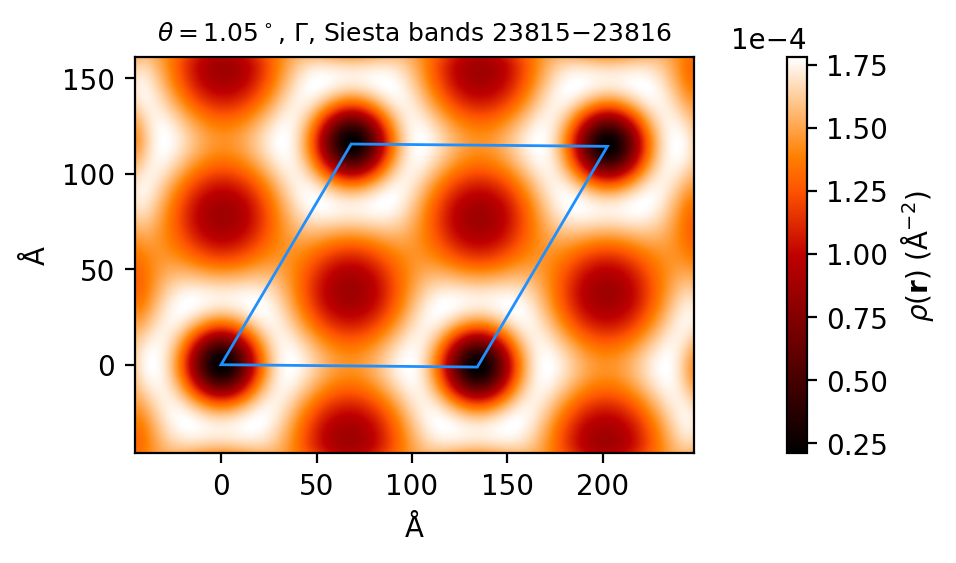

In [10]:
density = np.sum(np.sum(psi, axis=0) ** 2, axis=(0, 3)) * dz  # Total density (shape len(x) x len(y))
sublattice_density = np.sum(psi ** 2, axis=(1, 4)) * dz       # Density of each sublattice contribution (shape 4 x len(x) x len(y))

sigma = 5   # Width of the Gaussian (Angstrom). sigma / dx is the width of the Gaussian in number of gridpoints
smoothed = ndimage.gaussian_filter(density, sigma=sigma / dx, mode="wrap", cval=0.0, truncate=3.0)
smoothed_sublattice = [ndimage.gaussian_filter(d, sigma=sigma / dx, mode="wrap", cval=0.0, truncate=3.0) for d in sublattice_density]

if min(left_pad, right_pad, top_pad, bottom_pad) < 3 * sigma:
    print("Warning: the padding is smaller than 3 * sigma, so the edges of the grid affect the plot")

# Remove some padding (divide by dx to convert from Angstrom to grid points)
crop = (
    slice(int(round(left_pad // 10 / dx)), len(x) - int(round(right_pad // 10 / dx))),
    slice(int(round(bottom_pad // 10 / dx)), len(y) - int(round(top_pad // 10 / dx))),
)
x_plot, y_plot = x[crop[0]], y[crop[1]]
smoothed = smoothed[crop]
smoothed_sublattice = [d[crop] for d in smoothed_sublattice]

extent = [x_plot[0] - dx / 2, x_plot[-1] + dx / 2, y_plot[0] - dx / 2, y_plot[-1] + dx / 2]

moire_cell = [[0, 0], lattice[0][:2], (lattice[0] + lattice[1])[:2], lattice[1][:2]]

f, ax = plt.subplots(1, 1, figsize=(5, 2.7), dpi=200, layout="constrained")

p = ax.imshow(smoothed.T, origin="lower", extent=extent, cmap="gist_heat")
ax.add_patch(patches.Polygon(moire_cell, fill=False, edgecolor="dodgerblue", lw=1))
ax.set_aspect("equal")
ax.set_xlabel(r"$\mathrm{\AA}$")
ax.set_ylabel(r"$\mathrm{\AA}$")
cbar = f.colorbar(p, ax=ax, label=r"$\rho({\bf r})$ ($\mathrm{\AA}^{-2}$)")
cbar.formatter.set_powerlimits((0, 0))
ax.set_title(fr"$\theta = {angles(N):.2f}^\circ$, $\Gamma$, Siesta bands {siesta_indices[selected[0]]}$-${siesta_indices[selected[-1]]}", fontsize=9)
plt.show()

The density can also be resolved by sublattice. The four panels on the left show the density $\sum_n \int |\psi_{n,s}|^2\, dz$ of the contribution from each sublattice $s$, and the panel on the right shows the total density from above:

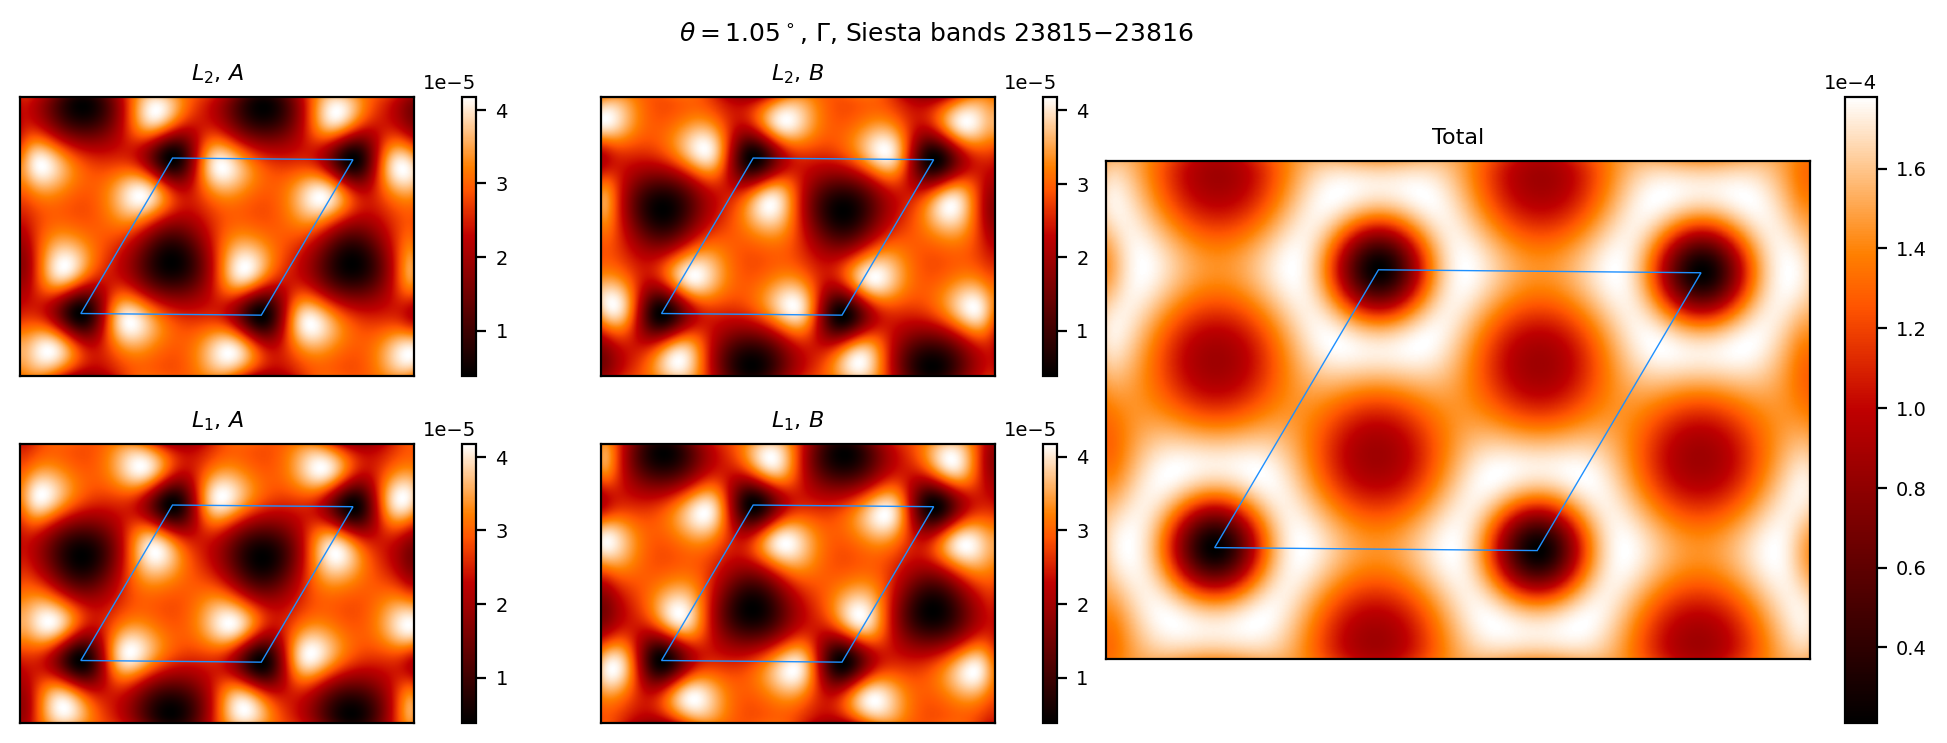

In [11]:
sublattice_titles = [r"$L_1$, $A$", r"$L_1$, $B$", r"$L_2$, $A$", r"$L_2$, $B$", "Total"]

fig = plt.figure(figsize=(10, 3.6), dpi=200, layout="constrained")
grid = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.5], height_ratios=[1, 1])
plot_grids = [grid[1, 0], grid[1, 1], grid[0, 0], grid[0, 1], grid[:, 2]]     # Top layer in the top row

for data, title, plot_grid in zip(smoothed_sublattice + [smoothed], sublattice_titles, plot_grids):
    ax = fig.add_subplot(plot_grid)
    p = ax.imshow(data.T, origin="lower", extent=extent, cmap="gist_heat")
    ax.add_patch(patches.Polygon(moire_cell, fill=False, edgecolor="dodgerblue", lw=0.5))
    ax.set_aspect("equal")
    ax.set_xticks([], [])
    ax.set_yticks([], [])
    ax.set_title(title, fontsize=8)
    cbar = fig.colorbar(p, ax=ax, pad=0.02)
    cbar.formatter.set_powerlimits((0, 0))
    cbar.ax.tick_params(labelsize=7)
    cbar.ax.yaxis.get_offset_text().set_fontsize(7)

plt.suptitle(fr"$\theta = {angles(N):.2f}^\circ$, $\Gamma$, Siesta bands {siesta_indices[selected[0]]}$-${siesta_indices[selected[-1]]}", fontsize=9)
plt.show()

## Zooming in to the atomic scale

Any grid can be passed to `wavefunction_at_points`. Below we use a finer grid around the maximum of the smoothed density from above to resolve the wavefunction density on the atomic scale, without smoothing. The dots show the atomic positions of the bottom (blue) and top (red) layers.

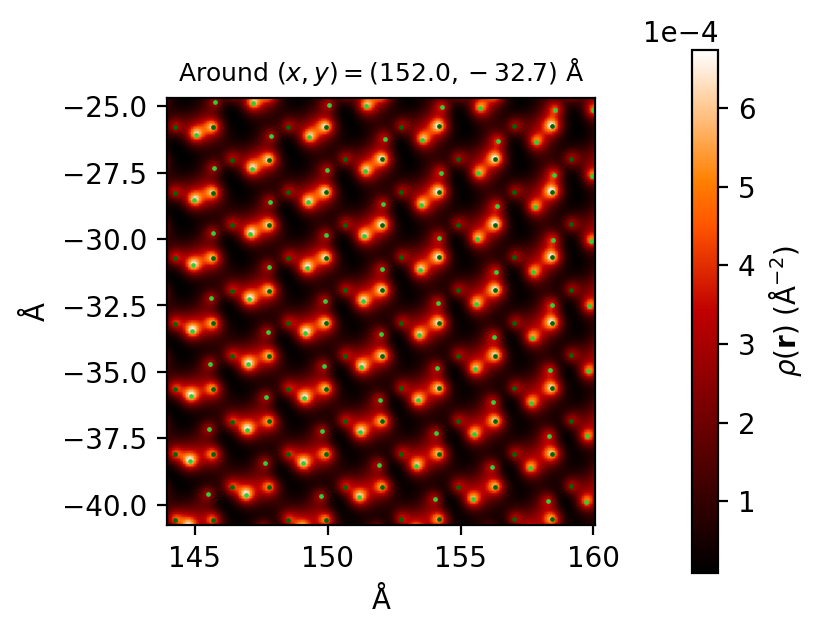

In [13]:
dx_zoom = 0.1     # In-plane grid spacing (Angstrom)
width = 16        # Width of the zoomed-in region (Angstrom)
i_max, j_max = np.unravel_index(np.argmax(smoothed), smoothed.shape)
x_zoom = x_plot[i_max] + np.arange(-width / 2, width / 2 + dx_zoom / 2, dx_zoom)
y_zoom = y_plot[j_max] + np.arange(-width / 2, width / 2 + dx_zoom / 2, dx_zoom)
X, Y, Z = np.meshgrid(x_zoom, y_zoom, z, indexing="ij")
zoom_points = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])

psi_zoom = wavefunction_at_points(zoom_points, coefficients[selected], positions, lattice, basis)
psi_zoom = psi_zoom.reshape(4, len(selected), len(x_zoom), len(y_zoom), len(z))
density_zoom = np.sum(np.sum(psi_zoom, axis=0) ** 2, axis=(0, 3)) * dz

# Atoms in the zoomed-in region, including periodic images
images = np.vstack([positions + n * lattice[0] + m * lattice[1] for n in (-1, 0, 1) for m in (-1, 0, 1)])
layer = np.tile(np.arange(n_atoms) >= n_atoms // 2, 9)
near = (np.abs(images[:, 0] - x_plot[i_max]) < width / 2) & (np.abs(images[:, 1] - y_plot[j_max]) < width / 2)

f, ax = plt.subplots(1, 1, figsize=(4, 3.2), dpi=200, layout="constrained")
extent_zoom = [x_zoom[0] - dx_zoom / 2, x_zoom[-1] + dx_zoom / 2, y_zoom[0] - dx_zoom / 2, y_zoom[-1] + dx_zoom / 2]
p = ax.imshow(density_zoom.T, origin="lower", extent=extent_zoom, cmap="gist_heat")
ax.scatter(images[near & ~layer, 0], images[near & ~layer, 1], s=0.5, color="darkgreen")
ax.scatter(images[near & layer, 0], images[near & layer, 1], s=0.5, color="limegreen")
ax.set_aspect("equal")
ax.set_xlabel(r"$\mathrm{\AA}$")
ax.set_ylabel(r"$\mathrm{\AA}$")
cbar = f.colorbar(p, ax=ax, label=r"$\rho({\bf r})$ ($\mathrm{\AA}^{-2}$)")
cbar.formatter.set_powerlimits((0, 0))
ax.set_title(fr"Around $(x, y) = ({x_plot[i_max]:.1f}, {y_plot[j_max]:.1f})~\mathrm{{\AA}}$", fontsize=9)
plt.show()